In [17]:
from src.clustering import Clustering, entropy_combi
from src.ampute_mar import AmputeMAR

import torch
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

# Breast Cancer Data

In [13]:
# Load data
data = load_breast_cancer(as_frame=True)#False)
X, y = data.data, data.target

### Amputation

In [14]:
# # MAR
# am = AmputeMAR()
# M = am.ampute(torch.tensor(X))[1]
# X = torch.tensor(X)

In [15]:
def build_patterns(columns, pattern_defs):
    """mice::ampute convention: 0 = set to missing, 1 = stays observed."""
    rows, freqs = [], []
    for missing_cols, freq in pattern_defs:
        missing = set(missing_cols)
        rows.append([0 if c in missing else 1 for c in columns])
        freqs.append(freq)
    patterns_df = pd.DataFrame(rows, columns=list(columns))
    return patterns_df, freqs

def r_ampute(df, mech, seed, patterns_df, freq_list):
    """Call mice::ampute on a pandas DataFrame, return a numpy array with NaNs."""
    import rpy2.robjects as ro
    from rpy2.robjects import pandas2ri
    from rpy2.robjects.conversion import localconverter
    from rpy2.robjects.packages import importr

    mice = importr("mice")   # cached by rpy2, so repeated calls are cheap

    with localconverter(ro.default_converter + pandas2ri.converter):
        r_df = ro.conversion.py2rpy(df)
        r_patterns = ro.conversion.py2rpy(patterns_df)
    r_freq = ro.FloatVector(freq_list)

    ro.r("set.seed")(int(seed))
    res = mice.ampute(r_df, prop=0.999, patterns=r_patterns, freq=r_freq, mech=mech)
    amp = res.rx2("amp")
    with localconverter(ro.default_converter + pandas2ri.converter):
        return ro.conversion.rpy2py(amp).to_numpy(dtype=float)


def mixed_ampute(X, c0, eps, pattern_defs, seed=0):
    rng = np.random.default_rng(seed)
    n = len(X)
    
    patterns_df, freq_list = build_patterns(X.columns, pattern_defs)
    
    complete = rng.random(n) < c0
    mnar = ~complete & (rng.random(n) < eps / (1 - c0))   # gives eps*n MNAR rows on average
    mar = ~complete & ~mnar

    out = X.to_numpy(dtype=float).copy()
    for mask, mech, s in [(mnar, "MNAR", seed), (mar, "MAR", seed + 1)]:
        if mask.sum() == 0:
            continue
        out[mask] = r_ampute(X[mask], mech, s, patterns_df, freq_list)

    X_amp = pd.DataFrame(out, columns=X.columns, index=X.index)
    return X_amp, complete, mnar, mar

In [18]:
# missingness patterns
cols = list(X.columns)
pattern_defs = [
    (["mean radius", "mean perimeter", "mean area"], 0.2),
    (["mean compactness", "mean concavity", "mean concave points"], 0.2),
    ([c for c in cols if c.startswith("worst")], 0.20),
    ([c for c in cols if c.endswith("error")], 0.20),
    ([c for c in cols if "radius" in c] + [c for c in cols if "area" in c] + [c for c in cols if "perimeter" in c], 0.2)
]

# MAR amputation
Xmis, complete, mnar, mar = mixed_ampute(X, c0=0.1, eps=0, seed=0, pattern_defs=pattern_defs)
M_np = (Xmis.notna()).astype(int).values
M = torch.tensor(M_np, dtype=torch.float32)
X = torch.tensor(X.to_numpy())

### Clustering code (unchanged)

In [19]:
# PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

In [21]:
# Clustering
# M = torch.ones_like(X)
cl = Clustering(X, M, k_range=(0,50), cov_type='diag', random_state=None)
cl.best_k # Check k_range

13

In [22]:
labels0 = cl.which_cluster(X, M) # GM K-clustering
labels_centers = cl.cluster_through_centers(X, M)
labels_entropy_combi = entropy_combi(tau=cl.get_resp(X, M), n_clusters=2).labels

In [58]:
#-------------------------
# Code for plotting
#-------------------------
# Combine labels
clusters = np.column_stack((labels_centers, labels0)).astype(int)

colors2 = [  # Warm: reds, pinks, purples, oranges, yellows
   # "#FFE5EC", 
    "#FF80AB", "#FF4081",# "#E91E63", "#C2185B",
    "#9C27B0", "#7B1FA2", "#4A148C", "#B71C1C", "#E53935",
    "#FF5722", "#FF8A33", "#FF9800", "#FDD835", "#FBC02D",
    "#CDDC39", "#7CB342", "#A0522D", "#6D4C41", "#4E0000"
]

colors1 = [  # Cool: blues, cyans, teals, greens, purples
    "#E3F2FD", "#90CAF9", "#42A5F5", "#2196F3", "#1E88E5",
    "#1565C0", "#0D47A1", "#06397A", "#00E5FF", "#00BCD4",
    "#0097A7", "#00838F", "#26A69A", "#43A047", "#9CCC65",
    "#7E57C2", "#5E35B1", "#8E24AA", "#3F51B5", "#0B1E3F"
]

# sort colors by blueness (only use purple if need to)
def blueness(hex_color):
    h = hex_color.lstrip('#')
    r, g, b = (int(h[i:i+2], 16) for i in (0, 2, 4))
    return b - max(r, g)

colors1 = sorted(colors1, key=blueness, reverse=True)

# Group mask
mask = labels_centers == 1

# Dense ranks within each group
_, rank1 = np.unique(clusters[mask, 1], return_inverse=True)
_, rank2 = np.unique(clusters[~mask, 1], return_inverse=True)

# Assign colors
colors = np.empty(len(X), dtype=object)
colors[mask] = np.asarray(colors1)[rank1]
colors[~mask] = np.asarray(colors2)[rank2]

# # Construct labels
# labs = np.array([
#     f"GM center {y} Cluster {x}"
#     for x, y in clusters
# ])

# # # Mapping: label -> color
# # color_map = dict(zip(labs, colors))

# # # One legend handle per unique label
# # unique_labs = list(color_map)

# # order = np.lexsort((clusters[:, 1], clusters[:, 0]))
# # unique_idx = np.unique(clusters, axis=0, return_index=True)[1]
# # unique_idx = unique_idx[np.argsort(clusters[unique_idx, 0] * (clusters[:, 1].max() + 1) + clusters[unique_idx, 1])]

# # unique_labs = labs[unique_idx]

# # handles = [
# #     Line2D([], [], marker="o", linestyle="", color="w",
# #            markerfacecolor=color_map[lab], label=lab, markersize=8)
# #     for lab in unique_labs
# # ]

mask1 = y == 1

# Assign marker shapes
markers = ['o' if m else 'x' for m in mask1]

# Custom legend: multiple colors under one label
class1_handles = tuple(
    Line2D([], [], marker='|', linestyle='None',
           color=c, markersize=7)
    for c in np.unique(colors[mask])
)

class2_handles = tuple(
    Line2D([], [], marker='|', linestyle='None',
           color=c, markersize=7)
    for c in np.unique(colors[~mask])
)

truth_handles = tuple(
    Line2D([], [], marker=m, markerfacecolor='none',
           markeredgecolor='gray', linestyle='None',
           markersize=7)
    for m in ['o', 'x']
)

handles = [
    truth_handles,
    class1_handles,
    class2_handles
]

labels = ['Truth: Benign / Malignant', 'GM Centers & KMeans Clustering: Class 1', 'GM Centers & KMeans Clustering: Class 2']

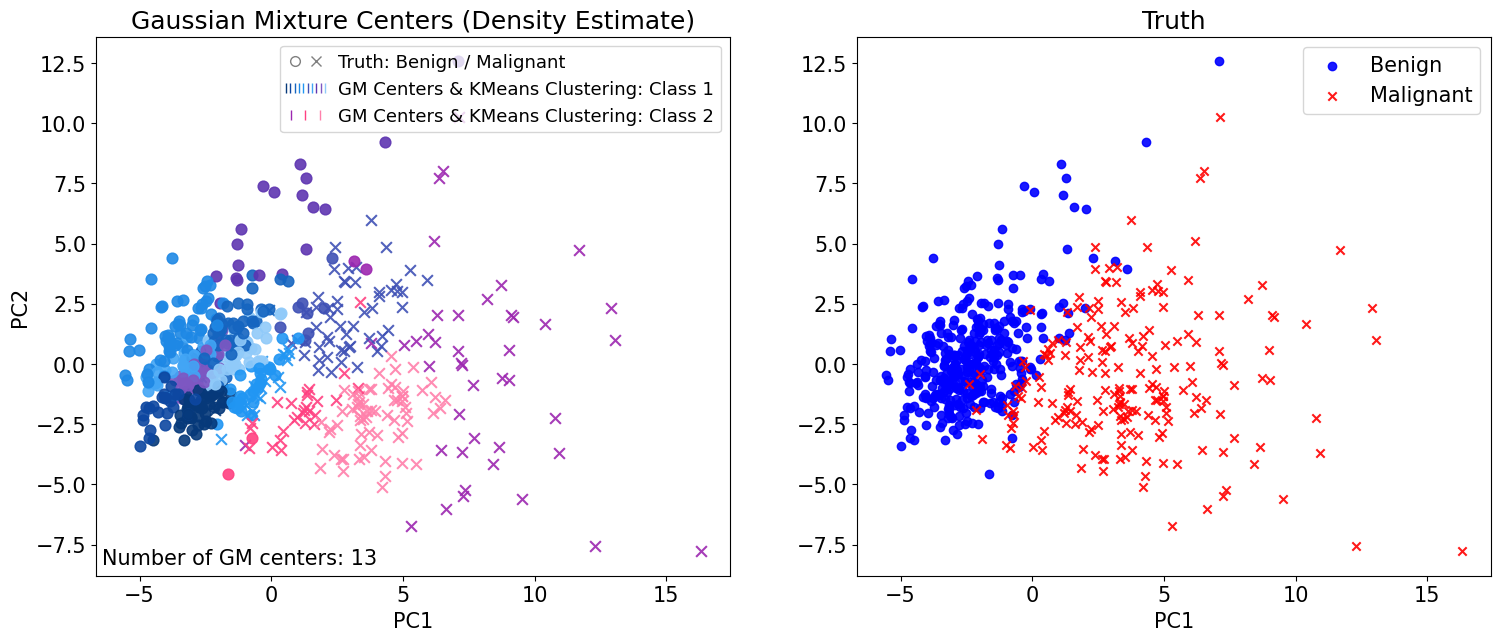

In [73]:
plt.rcParams.update({'font.size': 15})

_, axes = plt.subplots(1,2, figsize=(18,7))

for i in range(len(X)):
    axes[0].scatter(pcs[i, 0], pcs[i, 1], c=colors[i],
               marker=markers[i], s=60, alpha=0.9)

axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(handles, labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc='best', prop={'size': 13})
axes[0].set_title('Gaussian Mixture Centers (Density Estimate)')
axes[0].text(0.01, 0.05, f'Number of GM centers: {cl.best_k}',
             transform=axes[0].transAxes,
             ha='left', va='top')

axes[1].scatter(pcs[mask1,0], pcs[mask1,1], c='blue', alpha=0.9, label='Benign')
axes[1].scatter(pcs[~mask1,0], pcs[~mask1,1], marker='x', c='red', alpha=0.9, label = 'Malignant')
axes[1].set_title('Truth')
axes[1].set_xlabel("PC1")
axes[1].legend()

plt.savefig(
    'results/clustering1.png',
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()

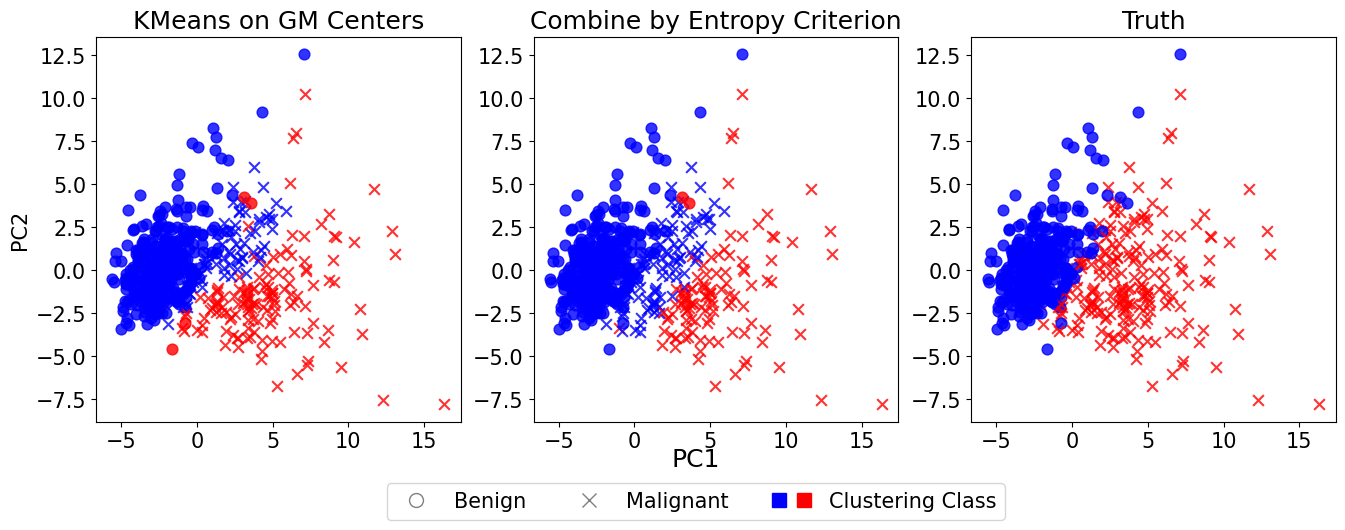

In [84]:
fig, axes = plt.subplots(1,3, figsize=(16,5), sharex=True)

for i in range(len(X)):
    axes[0].scatter(pcs[i, 0], pcs[i, 1], c=('blue' if labels_centers[i] else 'red'),
               marker=markers[i], s=60, alpha=0.8)
    axes[1].scatter(pcs[i, 0], pcs[i, 1], c=('red' if labels_entropy_combi[i] else 'blue'),
                   marker=markers[i], s=60, alpha=0.8)
    axes[2].scatter(pcs[i, 0], pcs[i, 1], c=('blue' if y[i] else 'red'),
                       marker=markers[i], s=60, alpha=0.8)

axes[0].set_title('KMeans on GM Centers')
axes[1].set_title('Combine by Entropy Criterion')
axes[2].set_title('Truth')
axes[0].set_ylabel("PC2")

truth_handles = tuple(
    Line2D([], [], marker=m, markerfacecolor='none',
           markeredgecolor='gray', linestyle='None',
           markersize=7)
    for m in ['o', 'x']
)

# axes[0].legend(handles=[], labels,
#     handler_map={tuple: HandlerTuple(ndivide=None)},
#     loc='best')

# axes[0].legend(
#     handles=[
#         Line2D([], [], marker='s', markerfacecolor=c,
#                markeredgecolor=c, linestyle='None',
#                markersize=3)
#         for c in ['blue', 'red']
#         ],
#     labels=['Class 1', 'Class 2'],
#     loc='best',
#     ncol=3,
#     handler_map={tuple: HandlerTuple(ndivide=None)}
# )

# axes[1].legend(
#     handles=[
#         Line2D([], [], marker='s', markerfacecolor=c,
#                markeredgecolor=c, linestyle='None',
#                markersize=3)
#         for c in ['blue', 'red']
#         ],
#     labels=['Class 1', 'Class 2'],
#     loc='best',
#     ncol=3,
#     handler_map={tuple: HandlerTuple(ndivide=None)}
# )

fig.legend(
    handles=[
        *[Line2D([], [], marker=m, markerfacecolor='none',
               markeredgecolor='gray', linestyle='None',
               markersize=10)
        for m in ['o', 'x']],
        tuple(
            Line2D([], [], marker='s', linestyle='None',
                color=c, markersize=10)
            for c in ['blue', 'red']
        )
        ],
    labels=['Benign', 'Malignant', 'Clustering Class'],
    loc='center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    handler_map={tuple: HandlerTuple(ndivide=None)}
)
fig.supxlabel("PC1")

plt.savefig('results/clustering2.png',dpi=300,
    bbox_inches="tight",)

plt.show()

On complete data

In [87]:
# Clustering on complete data
Mfull = torch.ones_like(X)
clfull = Clustering(X, Mfull, k_range=(0,50), cov_type='diag', random_state=8)
print(clfull.best_k) # Check k_range

labels0_f = clfull.which_cluster(X, Mfull)
labels_centers_f = clfull.cluster_through_centers(X, Mfull)
labels_entropy_combi_f = entropy_combi(tau=clfull.get_resp(X, Mfull), n_clusters=2).labels

12


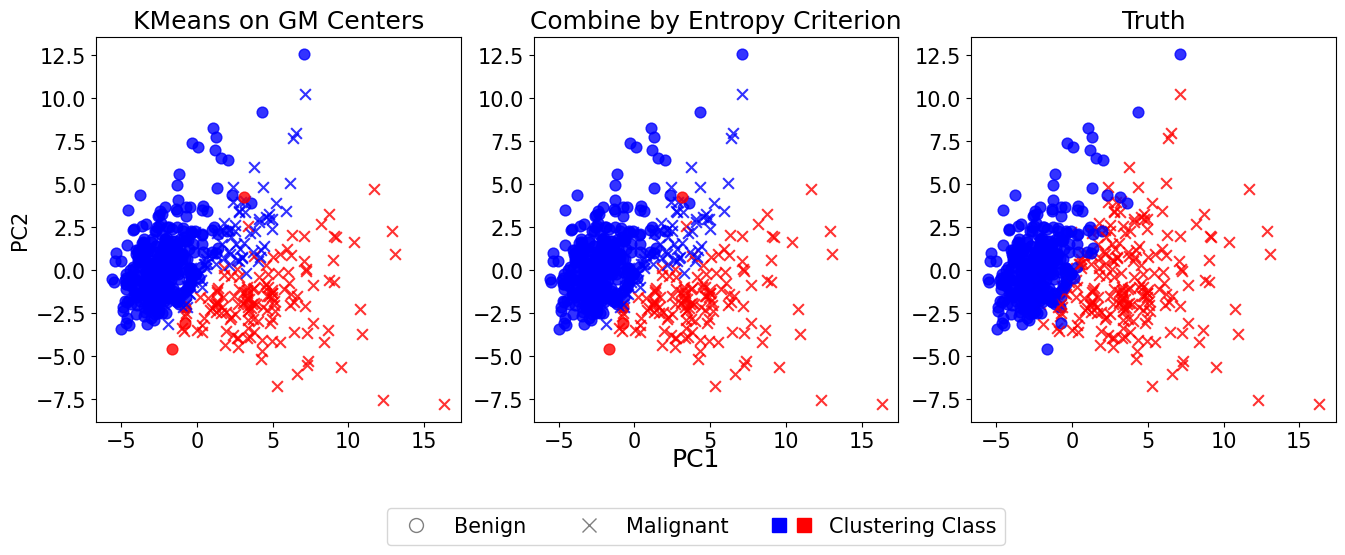

In [90]:
fig, axes = plt.subplots(1,3, figsize=(16,5), sharex=True)

for i in range(len(X)):
    axes[0].scatter(pcs[i, 0], pcs[i, 1], c=('blue' if labels_centers_f[i] else 'red'),
               marker=markers[i], s=60, alpha=0.8)
    axes[1].scatter(pcs[i, 0], pcs[i, 1], c=('blue' if labels_entropy_combi_f[i] else 'red'),
                   marker=markers[i], s=60, alpha=0.8)
    axes[2].scatter(pcs[i, 0], pcs[i, 1], c=('blue' if y[i] else 'red'),
                       marker=markers[i], s=60, alpha=0.8)

axes[0].set_title('KMeans on GM Centers')
axes[1].set_title('Combine by Entropy Criterion')
axes[2].set_title('Truth')
axes[0].set_ylabel("PC2")

truth_handles = tuple(
    Line2D([], [], marker=m, markerfacecolor='none',
           markeredgecolor='gray', linestyle='None',
           markersize=7)
    for m in ['o', 'x']
)

fig.legend(
    handles=[
        *[Line2D([], [], marker=m, markerfacecolor='none',
               markeredgecolor='gray', linestyle='None',
               markersize=10)
        for m in ['o', 'x']],
        tuple(
            Line2D([], [], marker='s', linestyle='None',
                color=c, markersize=10)
            for c in ['blue', 'red']
        )
        ],
    labels=['Benign', 'Malignant', 'Clustering Class'],
    loc='center',
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
    handler_map={tuple: HandlerTuple(ndivide=None)}
)
fig.supxlabel("PC1")

plt.savefig('results/clustering3.png',dpi=300,
    bbox_inches="tight",)

plt.show()

# Simulation

In [77]:
# Simulate data
n = 600
d = 30
norm1 = torch.distributions.MultivariateNormal(loc=torch.tensor([0.0, 0.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y1 = norm1.sample((n,))
norm2 = torch.distributions.MultivariateNormal(loc=torch.tensor([5.0, 5.0]), covariance_matrix=torch.tensor([[1.0,0.5], [0.5,1.0]]))
Y2 = norm2.sample((int(n/2),))

U = torch.distributions.Uniform(0,1).sample((2,30))

Xsim = Y1 @ U
idx = torch.randperm(n)[:int(n/2)]
Xsim[idx] = Y2 @ U
Xsim += torch.randn_like(Xsim)

In [78]:
am = AmputeMAR()
Msim = am.ampute(Xsim)[1]

In [79]:
true_labels = torch.ones(n)
true_labels[idx] = 2

Default of GMMMAR gives shared covariances of each center.

In [80]:
clsim = Clustering(Xsim, Msim, k_range=(0,20), cov_type='diag')
labels_centers_sim = clsim.cluster_through_centers(Xsim, Msim)

pcasim = PCA(n_components=2)
pcssim = pca.fit_transform(Xsim)

In [81]:
resp_sim = clsim.get_resp(Xsim, Msim)
labels_entropy_sim = entropy_combi(resp_sim, n_clusters=2).labels

In [82]:
print(clsim.log_prob_x(Xsim).sum())

tensor(-27588.2637)


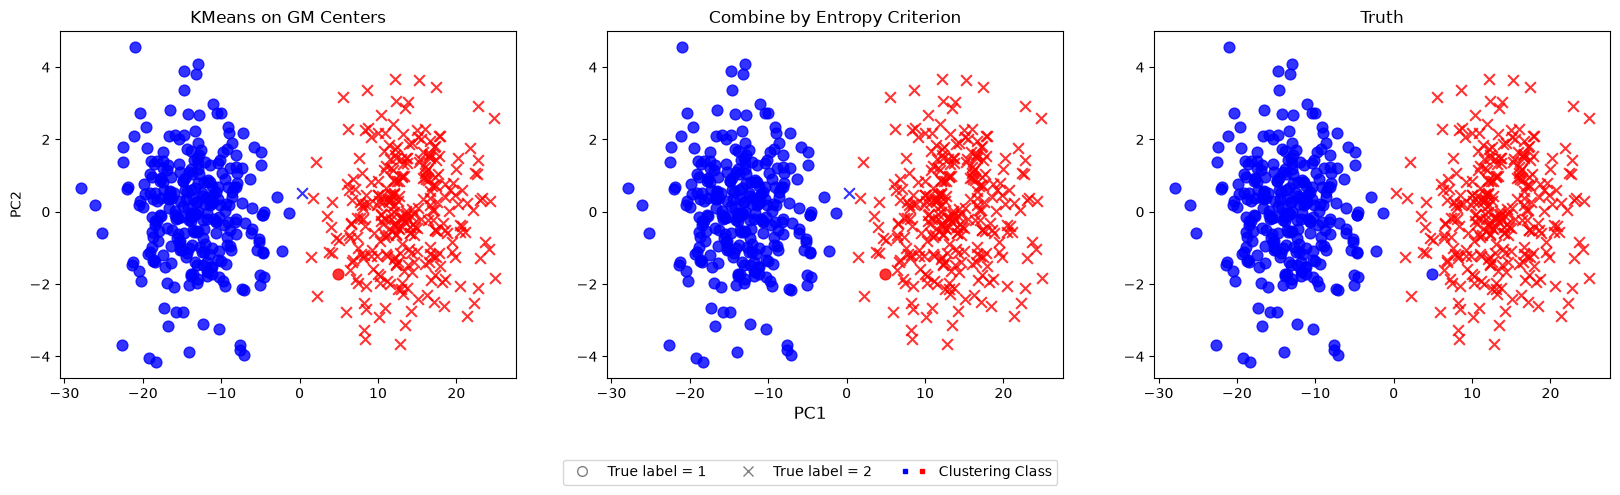

In [83]:
fig, axes = plt.subplots(1,3, figsize=(20,4.5), sharex=True)

markers_sim = ['o' if m else 'x' for m in true_labels==1]

for i in range(len(X)):
    axes[0].scatter(pcssim[i, 0], pcssim[i, 1], c=('blue' if labels_centers_sim[i] else 'red'),
               marker=markers_sim[i], s=60, alpha=0.8)
    axes[1].scatter(pcssim[i, 0], pcssim[i, 1], c=('red' if labels_entropy_sim[i] else 'blue'),
                   marker=markers_sim[i], s=60, alpha=0.8)
    axes[2].scatter(pcssim[i, 0], pcssim[i, 1], c=('blue' if true_labels[i]==1 else 'red'),
                       marker=markers_sim[i], s=60, alpha=0.8)

axes[0].set_title('KMeans on GM Centers')
axes[1].set_title('Combine by Entropy Criterion')
axes[2].set_title('Truth')
axes[0].set_ylabel("PC2")

truth_handles = tuple(
    Line2D([], [], marker=m, markerfacecolor='none',
           markeredgecolor='gray', linestyle='None',
           markersize=7)
    for m in ['o', 'x']
)

fig.legend(
    handles=[
        *[Line2D([], [], marker=m, markerfacecolor='none',
               markeredgecolor='gray', linestyle='None',
               markersize=7)
        for m in ['o', 'x']],
        tuple(
            Line2D([], [], marker='s', linestyle='None',
                color=c, markersize=3)
            for c in ['blue', 'red']
        )
        ],
    labels=['True label = 1', 'True label = 2', 'Clustering Class'],
    loc='center',
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
    handler_map={tuple: HandlerTuple(ndivide=None)}
)
fig.supxlabel("PC1")

plt.savefig('results/clusteringsim.png',dpi=300,
    bbox_inches="tight",)

plt.show()

In [84]:
# labels = cl.which_cluster(X, M)

# cmap = plt.get_cmap("tab10", len(np.unique(labels)))

# for k in np.unique(labels):
#     mask = labels == k
#     a = int(k in np.where(cl.center_labels==1)[0])
#     plt.scatter(
#         pcs[mask, 0],
#         pcs[mask, 1],
#         label=f"Cluster {k}, Group {a}",
#         alpha= (a + 1) / 2,
#         c=cmap(k),
#         edgecolors="black",
#         linewidths=0.3
#     )

# plt.xlabel("PC1")
# plt.ylabel("PC2")
# plt.legend(title="Clusters", loc="upper left", bbox_to_anchor=(1.02, 1))
# plt.show()